# Commodity Price Forecasting AI Agent
## Notebook 08 - Model Comparison & Ensemble

### Objective

This notebook compares the forecasting performance of all developed models using regression metrics. It also creates a simple ensemble forecast by averaging predictions from multiple machine learning models.

**Project:**Project 1D

**Author:**Ananya Bivare

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# =====================================================
# Load Prediction Files
# =====================================================

linear = pd.read_csv("../outputs/linear_regression_predictions.csv")

xgb = pd.read_csv("../outputs/xgboost_predictions.csv")

rf = pd.read_csv("../outputs/random_forest_predictions.csv")

print("Prediction files loaded successfully.")

Prediction files loaded successfully.


In [3]:
# =====================================================
# Metrics Function
# =====================================================

def evaluate(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

In [4]:
linear_mae, linear_rmse, linear_r2 = evaluate(

linear["Actual"],
linear["Predicted"]

)

xgb_mae, xgb_rmse, xgb_r2 = evaluate(

xgb["Actual"],
xgb["Predicted"]

)

rf_mae, rf_rmse, rf_r2 = evaluate(

rf["Actual"],
rf["Predicted"]

)

In [5]:
# =====================================================
# Comparison Table
# =====================================================

comparison = pd.DataFrame({

"Model":[

"Linear Regression",

"XGBoost",

"Random Forest"

],

"MAE":[

linear_mae,

xgb_mae,

rf_mae

],

"RMSE":[

linear_rmse,

xgb_rmse,

rf_rmse

],

"R2":[

linear_r2,

xgb_r2,

rf_r2

]

})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,0.042713,0.067237,0.999765
1,XGBoost,0.105081,0.155247,0.998746
2,Random Forest,0.058718,0.087996,0.999597


In [6]:
best = comparison.sort_values(

by="RMSE"

)

best

,Model,MAE,RMSE,R2
0,Linear Regression,0.042713,0.067237,0.999765
2,Random Forest,0.058718,0.087996,0.999597
1,XGBoost,0.105081,0.155247,0.998746


In [7]:
# =====================================================
# Ensemble
# =====================================================

ensemble_prediction = (

linear["Predicted"]

+

xgb["Predicted"]

+

rf["Predicted"]

)/3

In [8]:
ensemble_mae = mean_absolute_error(

linear["Actual"],
ensemble_prediction

)

ensemble_rmse = np.sqrt(

mean_squared_error(

linear["Actual"],
ensemble_prediction

)

)

ensemble_r2 = r2_score(

linear["Actual"],
ensemble_prediction

)

print("MAE :",round(ensemble_mae,4))

print("RMSE :",round(ensemble_rmse,4))

print("R² :",round(ensemble_r2,4))

MAE : 0.0571
RMSE : 0.0852
R² : 0.9996


In [9]:
comparison.loc[len(comparison)] = [

"Ensemble",

ensemble_mae,

ensemble_rmse,

ensemble_r2

]

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,0.042713,0.067237,0.999765
1,XGBoost,0.105081,0.155247,0.998746
2,Random Forest,0.058718,0.087996,0.999597
3,Ensemble,0.057093,0.085201,0.999622


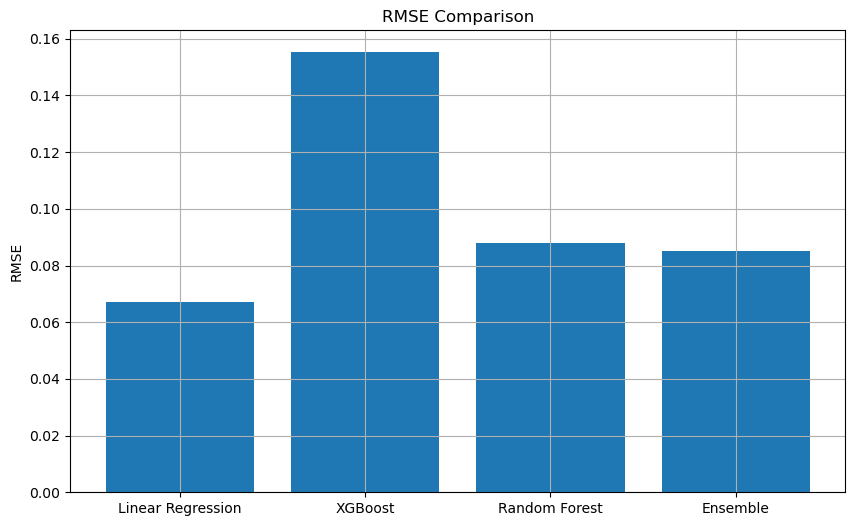

In [10]:
plt.figure(figsize=(10,6))

plt.bar(

comparison["Model"],

comparison["RMSE"]

)

plt.title("RMSE Comparison")

plt.ylabel("RMSE")

plt.grid(True)

plt.show()

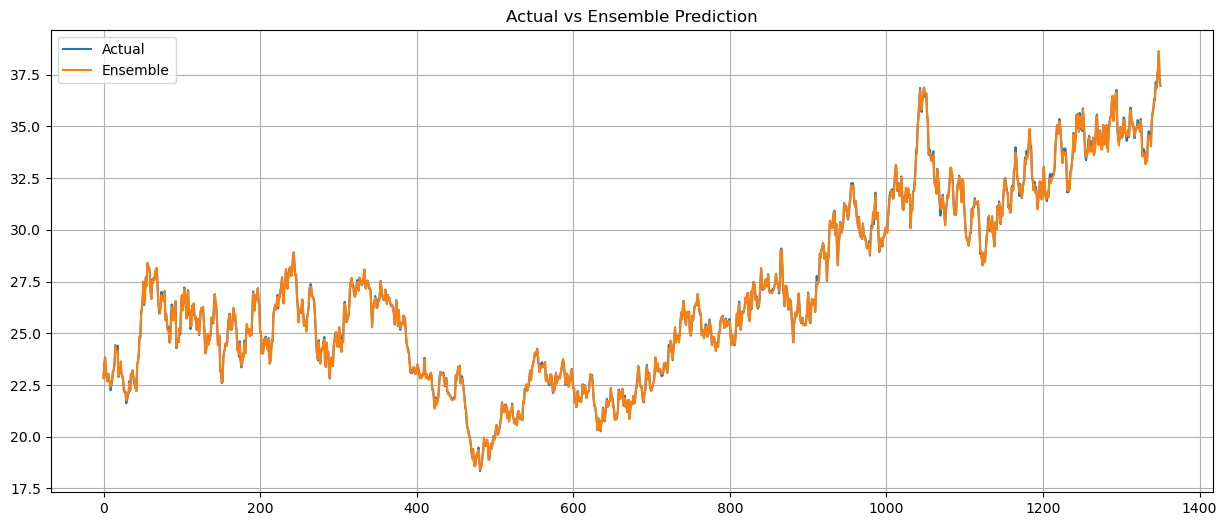

In [11]:
plt.figure(figsize=(15,6))

plt.plot(

linear["Actual"].values,

label="Actual"

)

plt.plot(

ensemble_prediction,

label="Ensemble"

)

plt.title("Actual vs Ensemble Prediction")

plt.legend()

plt.grid(True)

plt.show()

In [12]:
comparison.to_csv(

"../outputs/model_comparison.csv",

index=False

)

print("Model comparison saved.")

Model comparison saved.


In [13]:
ensemble = pd.DataFrame({

"Actual":linear["Actual"],

"Predicted":ensemble_prediction

})

ensemble.to_csv(

"../outputs/ensemble_predictions.csv",

index=False

)

print("Ensemble predictions saved.")

Ensemble predictions saved.


# Conclusion

Multiple forecasting models were evaluated using MAE, RMSE, and R² metrics. A simple ensemble model was created by averaging predictions from Linear Regression, XGBoost, and Random Forest. The comparison results were exported for reporting and dashboard development.